In [1]:
files = {
    "WT": (
        "Data/data/dataset/Ub_K11_mutants/Ub_wt_I/traj.gro",
        "Data/data/dataset/Ub_K11_mutants/Ub_wt_I/traj.xtc"
    ),
    "K11Q": (
        "Data/data/dataset/Ub_K11_mutants/Ub_K11Q_I/traj.gro",
        "Data/data/dataset/Ub_K11_mutants/Ub_K11Q_I/traj.xtc"
    ),
    "K11C": (
        "Data/data/dataset/Ub_K11_mutants/Ub_K11C_I/traj.gro",
        "Data/data/dataset/Ub_K11_mutants/Ub_K11C_I/traj.xtc"
    ),
    "K11Ac": (
        "Data/data/dataset/Ub_K11_mutants/Ub_K11Ac_I/traj.gro",
        "Data/data/dataset/Ub_K11_mutants/Ub_K11Ac_I/traj.xtc"
    )
}

In [3]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
import os

In [4]:
reference_traj = None
rmsf_data = {}
residue_indices = None

In [5]:
for name, (pdb_path, xtc_path) in files.items():
    
    print(f"Processing: {name}")
    traj = md.load(xtc_path, top=pdb_path)

    ca_indices = traj.topology.select('name CA')
    ca_traj = traj.atom_slice(ca_indices)

    if reference_traj is None:
        reference_traj = ca_traj
        residue_indices = [residue.index for residue in ca_traj.topology.residues]
    
    ca_traj.superpose(reference_traj)
    rmsf = md.rmsf(ca_traj, ca_traj, frame=0)
    rmsf_data[name] = rmsf



Processing: WT
Processing: K11Q
Processing: K11C
Processing: K11Ac


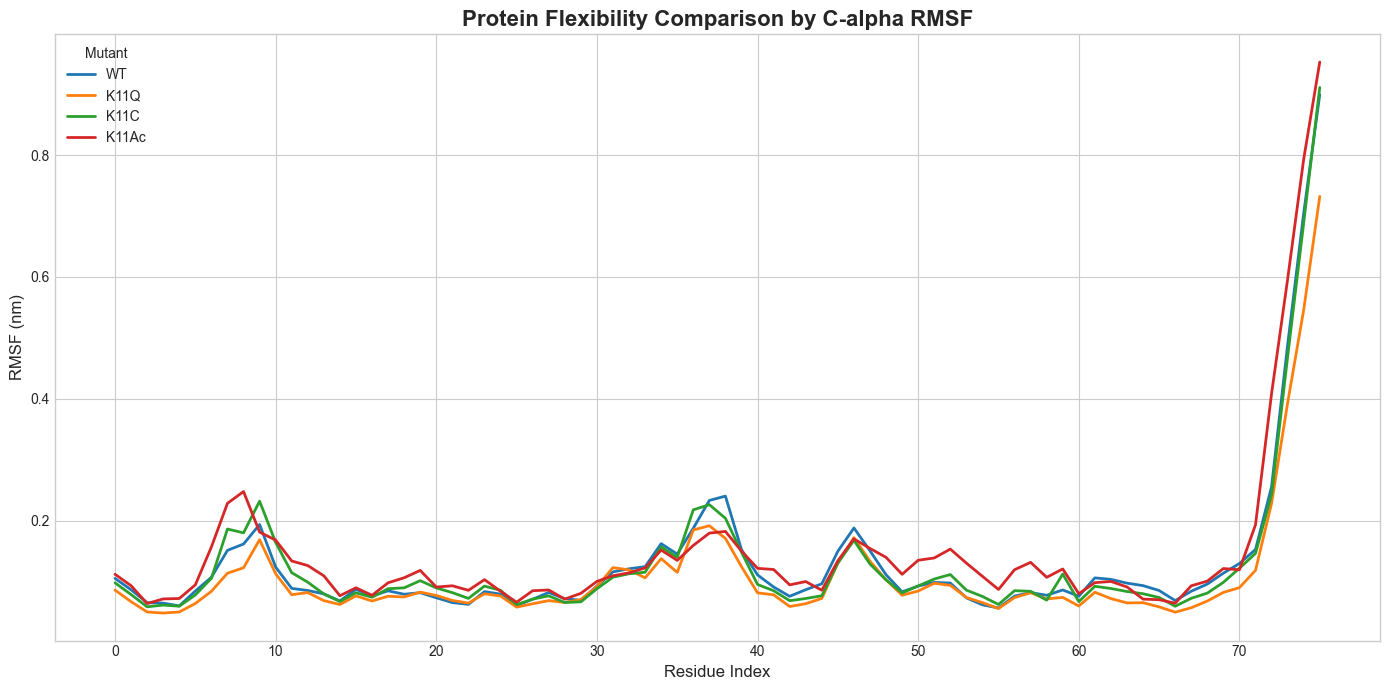

In [6]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(14, 7))

for name, rmsf_values in rmsf_data.items():
    ax.plot(residue_indices, rmsf_values, label=name, lw=2)

ax.set_title('Protein Flexibility Comparison by C-alpha RMSF', fontsize=16, weight='bold')
ax.set_xlabel('Residue Index', fontsize=12)
ax.set_ylabel('RMSF (nm)', fontsize=12)
ax.legend(title='Mutant', fontsize=10)
ax.grid(True)

plt.tight_layout()
plt.show()


Analysis complete.
Plot saved as phi_angle_analysis.png


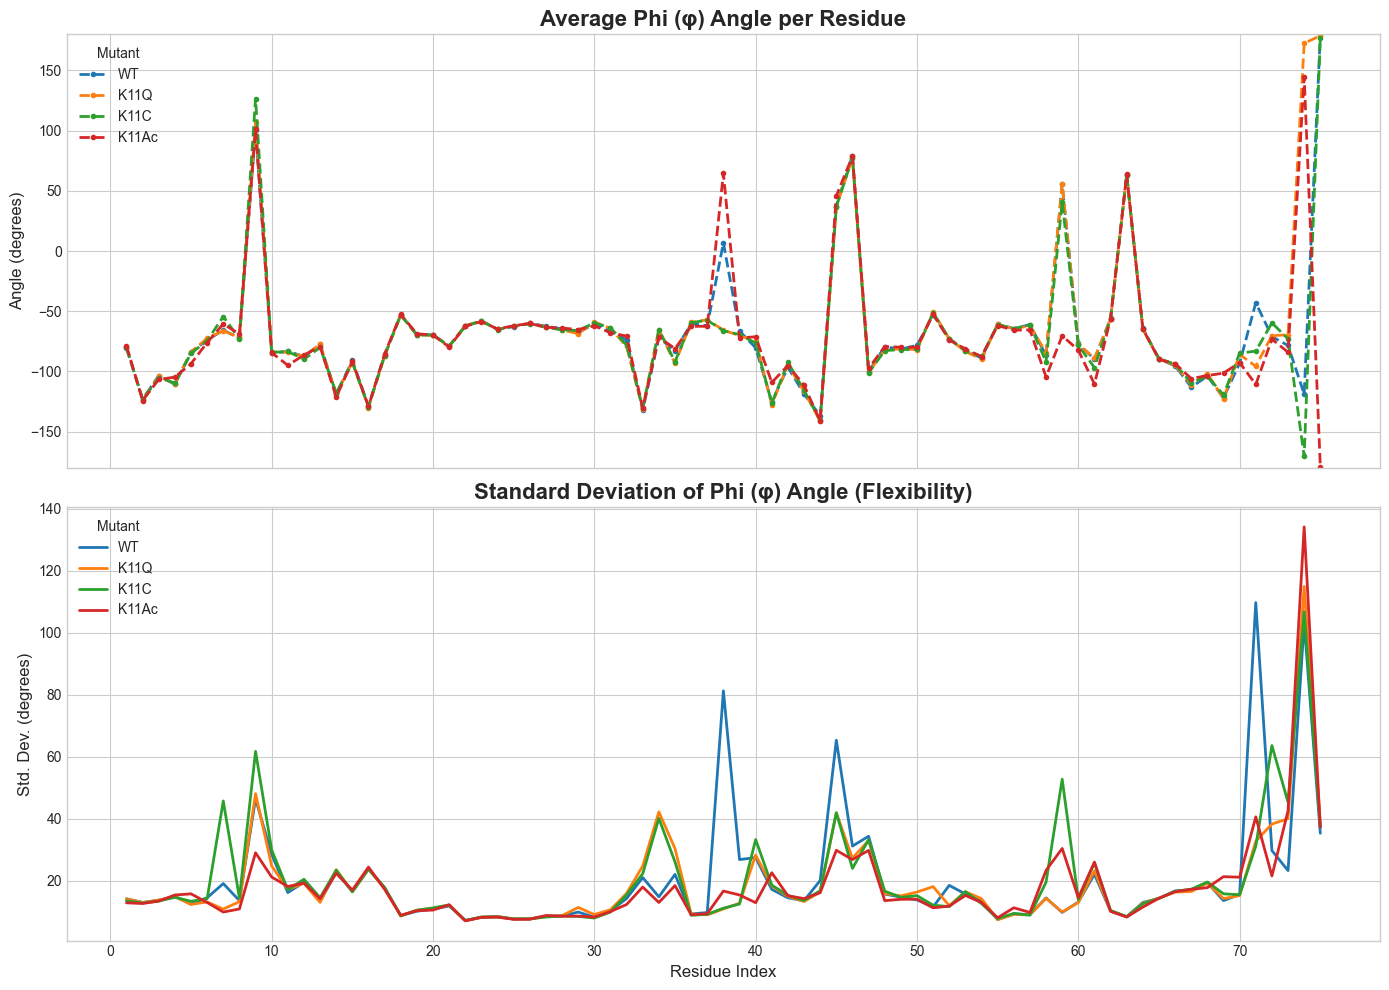

In [7]:
phi_means = {}
phi_stds = {}
residue_indices = None

for name, (top_path, traj_path) in files.items():
    print('Processing: ', name)
    traj = md.load(traj_path, top=top_path)
    
    if residue_indices is None and traj.n_residues > 0:
        residue_indices = [res.index for res in traj.topology.residues][1:]

    indices, angles_rad = md.compute_phi(traj)
    
    x_coords = np.cos(angles_rad)
    y_coords = np.sin(angles_rad)
    
    mean_x = np.mean(x_coords, axis=0)
    mean_y = np.mean(y_coords, axis=0)
    
    circular_mean_rad = np.arctan2(mean_y, mean_x)
    
    R = np.sqrt(mean_x**2 + mean_y**2)
    
    epsilon = 1e-8
    R = np.clip(R, 0, 1.0 - epsilon)
    circular_std_rad = np.sqrt(-2 * np.log(R))
    
    phi_means[name] = np.rad2deg(circular_mean_rad)
    phi_stds[name] = np.rad2deg(circular_std_rad)

print("Analysis complete.")

if phi_means and residue_indices is not None:
    plt.style.use('seaborn-v0_8-whitegrid')
    fig, (ax1, ax2) = plt.subplots(
        nrows=2, 
        ncols=1, 
        figsize=(14, 10), 
        sharex=True
    )

    for name, means in phi_means.items():
        ax1.plot(residue_indices, means, label=name, lw=2, marker='o', markersize=3, linestyle='--')
    ax1.set_title('Average Phi (φ) Angle per Residue', fontsize=16, weight='bold')
    ax1.set_ylabel('Angle (degrees)', fontsize=12)
    ax1.set_ylim(-180, 180)
    ax1.legend(title='Mutant')
    ax1.grid(True)

    for name, stds in phi_stds.items():
        ax2.plot(residue_indices, stds, label=name, lw=2)
    ax2.set_title('Standard Deviation of Phi (φ) Angle (Flexibility)', fontsize=16, weight='bold')
    ax2.set_xlabel('Residue Index', fontsize=12)
    ax2.set_ylabel('Std. Dev. (degrees)', fontsize=12)
    ax2.legend(title='Mutant')
    ax2.grid(True)

    plt.tight_layout()
    plt.savefig("phi_angle_analysis.png", dpi=300)
    print("Plot saved as phi_angle_analysis.png")
    # plt.show() # Uncomment this line if you want to display the plot interactively
else:
    print("No data was successfully processed to generate a plot.")

Generating combined mean and std. dev. plots...
Plot saved as phi_angle_mean_std_combined.png


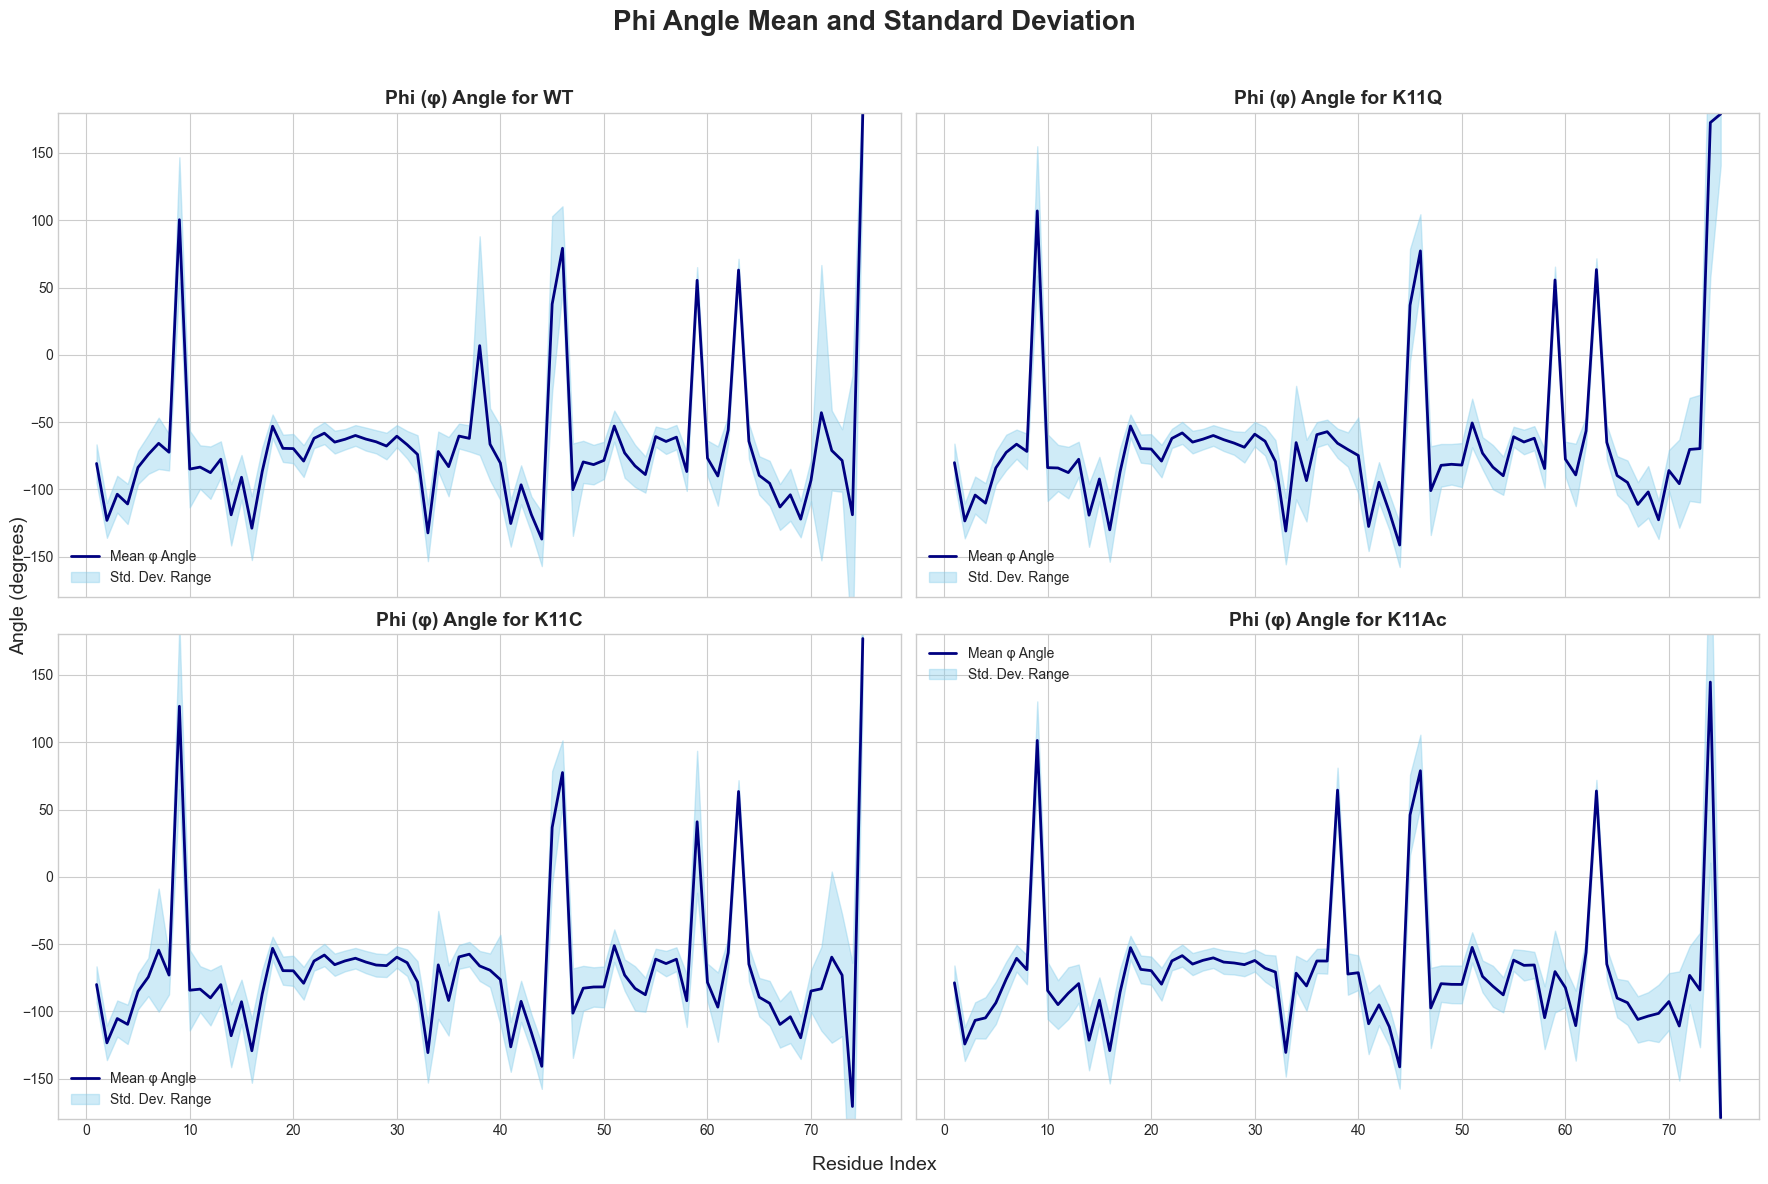

In [8]:
# --- 3. PLOTTING: Visualize the results in a combined plot ---
print("Generating combined mean and std. dev. plots...")

# Create a 2x2 grid for the 4 mutants
fig, axes = plt.subplots(
    nrows=2, 
    ncols=2, 
    figsize=(18, 12), 
    sharex=True, 
    sharey=True
)
# Flatten the 2x2 array of axes for easy iteration
axes = axes.flatten()

# Check if there's data to plot
if not phi_means:
    print("No data to plot.")
else:
    # Iterate through the mutants and plot each on a separate subplot
    for i, name in enumerate(files.keys()):
        ax = axes[i]
        
        # Ensure the mutant was processed successfully
        if name in phi_means and name in phi_stds:
            means = phi_means[name]
            stds = phi_stds[name]
            
            # Plot the mean as a solid line
            ax.plot(residue_indices, means, color='navy', lw=2, label='Mean φ Angle')
            
            # Create the shaded region for the standard deviation
            upper_bound = means + stds
            lower_bound = means - stds
            ax.fill_between(
                residue_indices, 
                lower_bound, 
                upper_bound, 
                color='skyblue', 
                alpha=0.4, 
                label='Std. Dev. Range'
            )
            
            ax.set_title(f'Phi (φ) Angle for {name}', fontsize=14, weight='bold')
            ax.grid(True)
            ax.legend()
        else:
            # Handle cases where a file might have failed to load
            ax.text(0.5, 0.5, f'{name}\n(No data)', ha='center', va='center', fontsize=12)

    # Set common labels and formatting for the entire figure
    fig.supxlabel('Residue Index', fontsize=14)
    fig.supylabel('Angle (degrees)', fontsize=14)
    fig.suptitle('Phi Angle Mean and Standard Deviation', fontsize=20, weight='bold')
    
    # Set the shared y-axis limits for all subplots
    plt.setp(axes, ylim=(-180, 180))

    # Clean up layout and save
    plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust for suptitle
    plt.savefig("phi_angle_mean_std_combined.png", dpi=300)
    print("Plot saved as phi_angle_mean_std_combined.png")

In [15]:
import mdtraj as md
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

# Suppress warnings from mdtraj about element inference
warnings.filterwarnings('ignore', category=UserWarning, module='mdtraj')

# --- 1. SETUP: Define file paths ---
files = {
    "WT": (
        "Data/data/dataset/Ub_K11_mutants/Ub_wt_I/traj.gro",
        "Data/data/dataset/Ub_K11_mutants/Ub_wt_I/traj.xtc"
    ),
    "K11Q": (
        "Data/data/dataset/Ub_K11_mutants/Ub_K11Q_I/traj.gro",
        "Data/data/dataset/Ub_K11_mutants/Ub_K11Q_I/traj.xtc"
    ),
    "K11C": (
        "Data/data/dataset/Ub_K11_mutants/Ub_K11C_I/traj.gro",
        "Data/data/dataset/Ub_K11_mutants/Ub_K11C_I/traj.xtc"
    ),
    "K11Ac": (
        "Data/data/dataset/Ub_K11_mutants/Ub_K11Ac_I/traj.gro",
        "Data/data/dataset/Ub_K11_mutants/Ub_K11Ac_I/traj.xtc"
    )
}

# --- 2. DATA EXTRACTION ---
# List to hold all our data before creating a DataFrame
all_data = []

print("Starting analysis... This may take a few minutes.")
for mutant_name, (top_path, traj_path) in files.items():
    print(f"Processing mutant: {mutant_name}")
    try:
        traj = md.load(traj_path, top=top_path)
        
        # --- A. Dihedral Angles ---
        print(f"  Calculating dihedrals for {mutant_name}...")
        dihedrals = {'phi': md.compute_phi(traj), 'psi': md.compute_psi(traj), 'omega': md.compute_omega(traj)}
        for name, (indices, angles_rad) in dihedrals.items():
            angles_deg = np.rad2deg(angles_rad)
            res_indices = [traj.topology.atom(i[0]).residue.index for i in indices]
            for frame_idx, frame_angles in enumerate(angles_deg):
                for res_idx, angle_val in zip(res_indices, frame_angles):
                    all_data.append({'mutant': mutant_name, 'residue_index': res_idx, 'parameter': name, 'value': angle_val})

        # --- B. Bond Lengths & Angles (Backbone) ---
        print(f"  Calculating bonds and angles for {mutant_name}...")
        bond_pairs = []
        angle_triplets = []
        for res in traj.topology.residues:
            try:
                # Get atoms for the current residue
                atom_N = res.atom('N')
                atom_CA = res.atom('CA')
                atom_C = res.atom('C')
                # Define C-alpha to C bond
                bond_pairs.append([atom_CA.index, atom_C.index])
                # Define N-Calpha-C angle
                angle_triplets.append([atom_N.index, atom_CA.index, atom_C.index])
            except KeyError:
                continue # Skip if an atom is not found (e.g., termini)

        # Calculate distances (in nm) and angles (in degrees)
        bond_lengths = md.compute_distances(traj, bond_pairs) * 10 # Convert nm to Angstrom
        bond_angles = np.rad2deg(md.compute_angles(traj, angle_triplets))
        
        res_indices_bonds = [traj.topology.atom(p[0]).residue.index for p in bond_pairs]
        res_indices_angles = [traj.topology.atom(t[1]).residue.index for t in angle_triplets]

        for frame_idx in range(traj.n_frames):
            for res_idx, val in zip(res_indices_bonds, bond_lengths[frame_idx]):
                 all_data.append({'mutant': mutant_name, 'residue_index': res_idx, 'parameter': 'CA-C bond (Å)', 'value': val})
            for res_idx, val in zip(res_indices_angles, bond_angles[frame_idx]):
                 all_data.append({'mutant': mutant_name, 'residue_index': res_idx, 'parameter': 'N-CA-C angle (°)', 'value': val})

    except Exception as e:
        print(f"Could not process {mutant_name}. Error: {e}")

# --- 3. DATA STRUCTURING ---
print("\nFinalizing data structure...")
df = pd.DataFrame(all_data)
if df.empty:
    print("No data was successfully processed. Exiting.")
else:
    # --- 4. PLOTTING ---
    parameters_to_plot = df['parameter'].unique()
    print(f"Generating plots for: {', '.join(parameters_to_plot)}")

    for param_name in parameters_to_plot:
        print(f"  Creating plot for {param_name}...")
        fig, ax = plt.subplots(figsize=(24, 10))
        
        # Filter data for the current parameter
        df_subset = df[df['parameter'] == param_name]
        
        # Determine a sensible number of residues to show to avoid clutter
        unique_residues = sorted(df_subset['residue_index'].unique())
        if len(unique_residues) > 30:
            # If too many residues, select a subset to keep the plot readable
            step = len(unique_residues) // 30
            selected_residues = unique_residues[::step]
            df_subset = df_subset[df_subset['residue_index'].isin(selected_residues)]
            plot_title = f'{param_name} Distribution (Sampled Residues)'
        else:
            plot_title = f'{param_name} Distribution'

        # Create the Violin plot for density
        sns.violinplot(data=df_subset, x='residue_index', y='value', hue='mutant', ax=ax, inner=None, palette='pastel', linewidth=1.5)
        # Overlay the Strip plot for individual points
        sns.stripplot(data=df_subset, x='residue_index', y='value', hue='mutant', ax=ax, dodge=True, jitter=0.2, size=1, alpha=0.1)

        # Formatting
        ax.set_title(plot_title, fontsize=20, weight='bold')
        ax.set_xlabel('Residue Index', fontsize=16)
        ax.set_ylabel(param_name, fontsize=16)
        if 'angle' in param_name: ax.set_ylim(-180, 180)

        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[:len(files)], labels[:len(files)], title='Mutant', fontsize=12)

        plt.tight_layout()
        filename = f"{param_name.replace(' ', '_').replace('(', '').replace(')', '').replace('°', 'deg')}_distribution.png"
        plt.savefig(filename, dpi=300)
        plt.close(fig) # Close the figure to free up memory
        print(f"    Saved plot to {filename}")

print("\nAll plots generated successfully.")

Starting analysis... This may take a few minutes.
Processing mutant: WT
  Calculating dihedrals for WT...
  Calculating bonds and angles for WT...
Processing mutant: K11Q
  Calculating dihedrals for K11Q...
  Calculating bonds and angles for K11Q...
Processing mutant: K11C
  Calculating dihedrals for K11C...
  Calculating bonds and angles for K11C...
Processing mutant: K11Ac
  Calculating dihedrals for K11Ac...
  Calculating bonds and angles for K11Ac...

Finalizing data structure...
Generating plots for: phi, psi, omega, CA-C bond (Å), N-CA-C angle (°)
  Creating plot for phi...
    Saved plot to phi_distribution.png
  Creating plot for psi...


C:\Users\goela\AppData\Local\Temp\ipykernel_8752\3917988426.py:126: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\goela\AppData\Local\Temp\ipykernel_8752\3917988426.py:128: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(filename, dpi=300)


    Saved plot to psi_distribution.png
  Creating plot for omega...


C:\Users\goela\AppData\Local\Temp\ipykernel_8752\3917988426.py:126: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\goela\AppData\Local\Temp\ipykernel_8752\3917988426.py:128: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(filename, dpi=300)


    Saved plot to omega_distribution.png
  Creating plot for CA-C bond (Å)...


C:\Users\goela\AppData\Local\Temp\ipykernel_8752\3917988426.py:126: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\goela\AppData\Local\Temp\ipykernel_8752\3917988426.py:128: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.savefig(filename, dpi=300)


    Saved plot to CA-C_bond_Å_distribution.png
  Creating plot for N-CA-C angle (°)...
    Saved plot to N-CA-C_angle_deg_distribution.png

All plots generated successfully.
